<a href="https://colab.research.google.com/github/oswrik/suscripcion_banco/blob/main/notebooks/02_modelos.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 02 · Pipeline y comparación de modelos (Producto 1)
**Métrica principal: recall.** Para el banco es más costoso perder a un cliente que sí contrataría un depósito a plazo que realizar una llamada telefónica sin éxito. Reportamos también el **ROC-AUC** como medida general.

In [2]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Datos: Bank Marketing (UCI, id 222)
URL = "https://raw.githubusercontent.com/oswrik/suscripcion_banco/refs/heads/main/data/bank-full.csv"

NUMERICAS = ["edad", "moroso", "saldo", "hipoteca", "prestamo",
             "dia", "campana", "dias_previos", "contactos_previos"]
CATEGORICAS = ["trabajo", "estado_civil", "educacion", "contacto", "mes", "resultado_previo"]

def cargar_datos():
    df = pd.read_csv(URL, sep=";")
    df.columns = [c.strip().lower() for c in df.columns]
    df = df.rename(columns={
        "age": "edad", "job": "trabajo", "marital": "estado_civil",
        "education": "educacion", "default": "moroso", "balance": "saldo",
        "housing": "hipoteca", "loan": "prestamo", "contact": "contacto",
        "day": "dia", "month": "mes", "campaign": "campana",
        "pdays": "dias_previos", "previous": "contactos_previos",
        "poutcome": "resultado_previo"})
    for col in ["moroso", "hipoteca", "prestamo"]:
        df[col] = (df[col].str.strip() == "yes").astype(int)
    df["suscribe"] = (df["y"].str.strip() == "yes").astype(int)
    return df[NUMERICAS + CATEGORICAS + ["suscribe"]]

df = cargar_datos()
X, y = df[NUMERICAS + CATEGORICAS], df["suscribe"]
print(df.shape, f"| suscriben: {y.mean():.1%}")

(45211, 16) | suscriben: 11.7%


In [3]:
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Misma división en todos los notebooks: el test se usa una sola vez, al final
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

def preprocesador():
    num = Pipeline([("imputar", SimpleImputer(strategy="median")), ("escalar", StandardScaler())])
    cat = Pipeline([("imputar", SimpleImputer(strategy="most_frequent")),
                    ("onehot", OneHotEncoder(handle_unknown="ignore"))])
    return ColumnTransformer([("num", num, NUMERICAS), ("cat", cat, CATEGORICAS)])

## Los 5 modelos, con validación cruzada estratificada de 5 folds

In [4]:
from sklearn.model_selection import cross_validate
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from lightgbm import LGBMClassifier

modelos = {
    "Baseline (clase mayoritaria)": DummyClassifier(),
    "Regresión logística (L2)": LogisticRegression(max_iter=1000, class_weight="balanced"),
    "k-NN (k = 15)": KNeighborsClassifier(n_neighbors=15),
    "Random Forest": RandomForestClassifier(n_estimators=300, class_weight="balanced", random_state=42, n_jobs=-1),
    "LightGBM": LGBMClassifier(class_weight="balanced", random_state=42, verbose=-1),
}
filas = []
for nombre, m in modelos.items():
    r = cross_validate(Pipeline([("prep", preprocesador()), ("modelo", m)]), X_tr, y_tr, cv=cv,
                       scoring={"recall": "recall", "auc": "roc_auc"})
    filas.append({"modelo": nombre,
                  "recall": f"{r['test_recall'].mean():.3f} ± {r['test_recall'].std():.3f}",
                  "ROC-AUC": f"{r['test_auc'].mean():.3f} ± {r['test_auc'].std():.3f}"})
tabla = pd.DataFrame(filas)
tabla

,modelo,recall,ROC-AUC
0,Baseline (clase mayoritaria),0.000 ± 0.000,0.500 ± 0.000
1,Regresión logística (L2),0.622 ± 0.010,0.764 ± 0.003
2,k-NN (k = 15),0.155 ± 0.010,0.730 ± 0.005
3,Random Forest,0.205 ± 0.012,0.780 ± 0.005
4,LightGBM,0.618 ± 0.006,0.796 ± 0.003


## Elección del modelo
Gana **LightGBM**: obtiene el mayor **recall** y el mayor **ROC-AUC** al capturar interacciones no lineales entre el historial de campañas, la estacionalidad y las variables financieras.

**Para el Producto 2:** intentaremos mejorar aún más LightGBM optimizando sus hiperparámetros con Optuna y comparándolo *fold a fold*.

## Evaluación final en el test (una sola vez)

Test · recall = 0.635 · ROC-AUC = 0.802


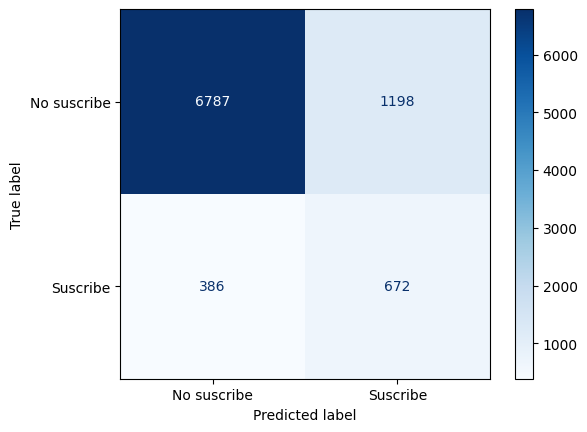

In [5]:
from sklearn.metrics import recall_score, roc_auc_score, ConfusionMatrixDisplay
mejor = Pipeline([("prep", preprocesador()), ("modelo", modelos["LightGBM"])]).fit(X_tr, y_tr)
prob = mejor.predict_proba(X_te)[:, 1]
print(f"Test · recall = {recall_score(y_te, mejor.predict(X_te)):.3f} · ROC-AUC = {roc_auc_score(y_te, prob):.3f}")
ConfusionMatrixDisplay.from_estimator(mejor, X_te, y_te, display_labels=["No suscribe", "Suscribe"], cmap="Blues")
plt.show()